# Task 3: Regression Model for Prediction
## California Housing Dataset — Linear Regression

**Objective:** Predict house values using housing features, evaluate the model, and visualize actual versus predicted values.

**Tools:** Python, Pandas, Matplotlib, scikit-learn.

In [ ]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 2. Load dataset
housing = fetch_california_housing(as_frame=True)
X = housing.data
y = housing.target  # Target is in units of $100,000

print("Dataset shape:", X.shape)
print("Features:", list(X.columns))
display(X.head())
display(y.describe())

Dataset shape: (20640, 8)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


,MedHouseVal
count,20640.000000
mean,2.068558
std,1.153956
min,0.149990
25%,1.196000
50%,1.797000
75%,2.647250
max,5.000010


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
# 3. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16512
Testing samples: 4128


In [ ]:
# 4. Train model and predict
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# 5. Evaluate performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print("Regression Model Evaluation")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R-squared (R²): {r2:.3f}")
print("Target values are measured in units of $100,000.")

Regression Model Evaluation
MAE: 0.533
RMSE: 0.746
R-squared (R²): 0.576
Target values are measured in units of $100,000.


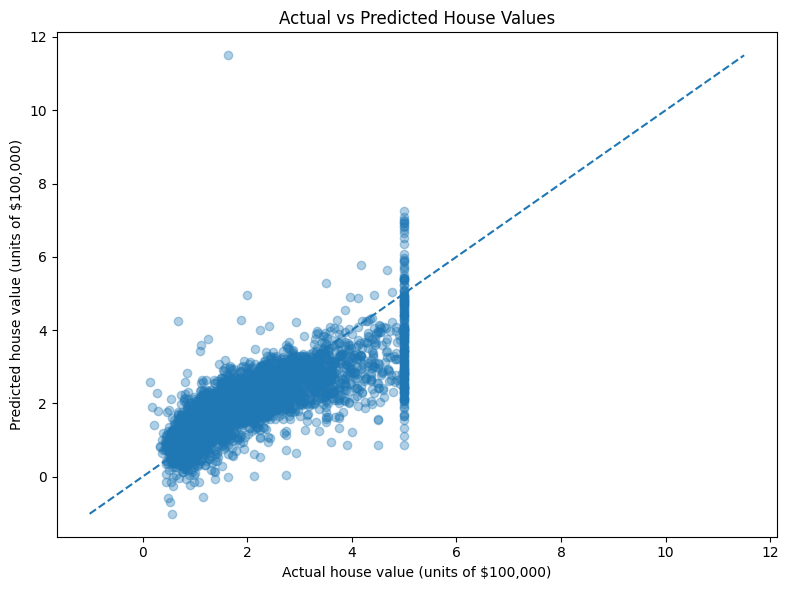

In [ ]:
# 6. Plot actual versus predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.35)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual house value (units of $100,000)")
plt.ylabel("Predicted house value (units of $100,000)")
plt.title("Actual vs Predicted House Values")
plt.tight_layout()
plt.show()

In [ ]:
# 7. Compare a few actual and predicted values
comparison = pd.DataFrame({
    "Actual value": y_test.iloc[:10].values,
    "Predicted value": y_pred[:10]
})
display(comparison.round(3))

,Actual value,Predicted value
0,0.477,0.719
1,0.458,1.764
2,5.000,2.710
3,2.186,2.839
4,2.780,2.605
5,1.587,2.012
6,1.982,2.646
7,1.575,2.169
8,3.400,2.741
9,4.466,3.916


## Brief Explanation of Results

- **MAE (Mean Absolute Error):** Average absolute difference between actual and predicted values. Lower is better.
- **RMSE (Root Mean Squared Error):** Penalizes larger errors more strongly. Lower is better.
- **R² (R-squared):** Indicates how much variation in house values is explained by the model. Values closer to 1 generally indicate a better fit.

In the scatter plot, points closer to the dashed diagonal line indicate more accurate predictions.

## Conclusion

A Linear Regression model was trained on the California Housing dataset. The data was split into training and testing sets, predictions were made on unseen test data, and the model was evaluated using MAE, RMSE, and R². After running the notebook, add your actual metric values to your report.

**Dataset note:** The target represents median house value in units of $100,000. An internet connection may be needed the first time scikit-learn downloads this dataset.